# BNN logEI Completed Results

Analysis-only notebook for the completed BNN online campaign.

This notebook does not build optimizers, submit queue jobs, run HFSS, train BNNs, or write checkpoints. It only reads finished artifacts from `experiments/bnn_online_general/` and produces summary tables and plots.


In [1]:
from __future__ import annotations

from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import yaml

CWD = Path.cwd().resolve()
if (CWD / 'configs').exists() and (CWD / 'experiments').exists():
    REPO_ROOT = CWD
elif (CWD.parent / 'configs').exists() and (CWD.parent / 'experiments').exists():
    REPO_ROOT = CWD.parent
else:
    raise RuntimeError(f'Cannot locate repo root from cwd={CWD}')

print('repo root:', REPO_ROOT)


repo root: /home/zhanghf/projects/vector


In [2]:
# Result loading controls
SEEDS = [0, 1, 2, 3, 4]
N_INIT = 30
BUDGET = 50
TARGET_TRIALS = N_INIT + BUDGET
LOAD_COMPLETED_ONLY = True
SELECTED_SEED = None  # None selects the latest completed seed found in SEEDS.

METHOD_LABEL = 'bnn_response_qlogei'
CONFIG_PATH = REPO_ROOT / 'configs' / 'filter_bnn_online_uaw_uaw.yaml'
OUTPUT_DIR = REPO_ROOT / 'experiments' / 'bnn_online_general'
CAMPAIGN_SUMMARY_PATH = OUTPUT_DIR / 'campaign_summary.csv'

COMPARISON_METHOD_ROOTS = {
    'BO logEI': REPO_ROOT / 'experiments' / 'bo_online_general',
    'LHS': REPO_ROOT / 'experiments' / 'lhs_online_general',
    'BNN logEI': OUTPUT_DIR,
}

print('output:', OUTPUT_DIR)
print('campaign_summary:', CAMPAIGN_SUMMARY_PATH, 'exists=', CAMPAIGN_SUMMARY_PATH.exists())
print('seeds:', SEEDS)
print('target_trials:', TARGET_TRIALS)
print('load_completed_only:', LOAD_COMPLETED_ONLY)


output: /home/zhanghf/projects/vector/experiments/bnn_online_general
campaign_summary: /home/zhanghf/projects/vector/experiments/bnn_online_general/campaign_summary.csv exists= True
seeds: [0, 1, 2, 3, 4]
target_trials: 80
load_completed_only: True


In [3]:
VARIABLE_ORDER = ['L', 'L1', 'L2', 'W', 'W1', 'W2', 'S1', 'S2']

if CONFIG_PATH.exists():
    with CONFIG_PATH.open('r', encoding='utf-8') as f:
        cfg = yaml.safe_load(f)
    reg_min = list(cfg['data']['regularization']['min'])
    reg_max = list(cfg['data']['regularization']['max'])
    if len(reg_min) == len(VARIABLE_ORDER) + 1:
        reg_min = reg_min[:len(VARIABLE_ORDER)]
        reg_max = reg_max[:len(VARIABLE_ORDER)]
    if len(reg_min) != len(VARIABLE_ORDER):
        raise ValueError(
            f'Regularization dimension mismatch: len(min)={len(reg_min)} '
            f'variable_order={len(VARIABLE_ORDER)}'
        )
    variable_bounds = {
        name: (float(reg_min[i]), float(reg_max[i]))
        for i, name in enumerate(VARIABLE_ORDER)
    }
    display(pd.DataFrame({
        'variable': VARIABLE_ORDER,
        'low': [variable_bounds[k][0] for k in VARIABLE_ORDER],
        'high': [variable_bounds[k][1] for k in VARIABLE_ORDER],
    }))
else:
    cfg = {}
    variable_bounds = {}
    print(f'Config not found; variable bounds skipped: {CONFIG_PATH}')


,variable,low,high
0,L,7.70,7.90
1,L1,8.00,8.20
2,L2,7.80,8.00
3,W,0.90,1.10
4,W1,0.70,0.90
5,W2,0.90,1.10
6,S1,0.13,0.16
7,S2,0.55,0.60


In [4]:
def run_id_for_seed(seed: int) -> str:
    return f'bnn_online_general_seed{int(seed)}'


def checkpoint_for_seed(seed: int, root: Path = OUTPUT_DIR) -> Path:
    return root / f'{run_id_for_seed(seed)}.checkpoint.json'


def checkpoint_history(path: Path) -> list[dict]:
    payload = json.loads(path.read_text(encoding='utf-8'))
    history = payload.get('history', [])
    return history if isinstance(history, list) else []


def _seed_from_checkpoint_path(path: Path, payload: dict | None = None) -> int | None:
    if payload is not None and payload.get('seed') is not None:
        return int(payload['seed'])
    match = re.match(r'.*_seed(\d+)\.checkpoint\.json$', path.name)
    return int(match.group(1)) if match else None


def history_frame(seed: int, history: list[dict], *, method: str = METHOD_LABEL) -> pd.DataFrame:
    hist = pd.DataFrame(history)
    if hist.empty:
        return hist
    hist = hist.copy()
    hist['seed'] = int(seed)
    hist['method'] = method
    if 'iteration' in hist:
        hist['iteration'] = pd.to_numeric(hist['iteration'], errors='coerce')
        hist = hist[np.isfinite(hist['iteration'])].copy()
        hist['iteration'] = hist['iteration'].astype(int)
        hist = hist.sort_values('iteration').reset_index(drop=True)
    return hist


def load_campaign_summary(path: Path = CAMPAIGN_SUMMARY_PATH) -> pd.DataFrame:
    if not path.exists():
        return pd.DataFrame()
    df = pd.read_csv(path)
    if 'seed' in df.columns:
        df = df.sort_values('seed').reset_index(drop=True)
    return df


def load_seed_histories(
    seeds: list[int],
    *,
    root: Path = OUTPUT_DIR,
    completed_only: bool = LOAD_COMPLETED_ONLY,
    method: str = METHOD_LABEL,
) -> tuple[list[pd.DataFrame], pd.DataFrame]:
    frames: list[pd.DataFrame] = []
    skipped: list[dict] = []
    for seed in seeds:
        seed = int(seed)
        path = checkpoint_for_seed(seed, root)
        if not path.exists():
            skipped.append({'seed': seed, 'reason': 'missing_checkpoint', 'checkpoint': str(path), 'num_trials': 0})
            continue
        payload = json.loads(path.read_text(encoding='utf-8'))
        history = payload.get('history', [])
        history = history if isinstance(history, list) else []
        num_trials = len(history)
        if completed_only and num_trials < TARGET_TRIALS:
            skipped.append({'seed': seed, 'reason': 'incomplete', 'checkpoint': str(path), 'num_trials': num_trials})
            continue
        frame = history_frame(seed, history, method=method)
        if frame.empty:
            skipped.append({'seed': seed, 'reason': 'empty_history', 'checkpoint': str(path), 'num_trials': num_trials})
            continue
        frames.append(frame)
    return frames, pd.DataFrame(skipped)


def select_history_frame(frames: list[pd.DataFrame], seed: int | None = SELECTED_SEED) -> pd.DataFrame:
    if not frames:
        return pd.DataFrame()
    if seed is not None:
        for frame in frames:
            if int(frame['seed'].iloc[0]) == int(seed):
                return frame.copy()
        return pd.DataFrame()
    return frames[-1].copy()


def first_feasible_iteration(history_df: pd.DataFrame) -> int | None:
    if history_df.empty or 'feasible' not in history_df or 'iteration' not in history_df:
        return None
    feasible_idx = history_df.index[history_df['feasible'] == True].tolist()  # noqa: E712
    return int(history_df.loc[feasible_idx[0], 'iteration']) if feasible_idx else None


def best_objective_from_history(history_df: pd.DataFrame) -> float:
    if history_df.empty:
        return float('nan')
    if 'best_so_far' in history_df:
        best = pd.to_numeric(history_df['best_so_far'], errors='coerce')
        if np.isfinite(best).any():
            return float(np.nanmin(best))
    if 'objective' in history_df:
        objective = pd.to_numeric(history_df['objective'], errors='coerce')
        if np.isfinite(objective).any():
            return float(np.nanmin(objective))
    return float('nan')


In [5]:
campaign_summary_df = load_campaign_summary()
seed_history_frames, skipped_seed_results = load_seed_histories(SEEDS)
all_hist_df = (
    pd.concat(seed_history_frames, ignore_index=True)
    if seed_history_frames
    else pd.DataFrame()
)
history_df = select_history_frame(seed_history_frames)

print('completed_seed_histories:', len(seed_history_frames))
print('combined_history_rows:', len(all_hist_df))
if not history_df.empty:
    print('selected_seed:', int(history_df['seed'].iloc[0]))

if not campaign_summary_df.empty:
    print('Campaign summary:')
    display(campaign_summary_df)
else:
    print(f'No campaign summary found at {CAMPAIGN_SUMMARY_PATH}')

if not skipped_seed_results.empty:
    print('Skipped seed checkpoints:')
    display(skipped_seed_results)

if not all_hist_df.empty:
    per_seed_summary = (
        all_hist_df
        .groupby('seed', as_index=False)
        .agg(
            num_trials=('iteration', 'count'),
            last_iteration=('iteration', 'max'),
            best_objective=('best_so_far', lambda s: pd.to_numeric(s, errors='coerce').min()),
        )
        .sort_values('seed')
        .reset_index(drop=True)
    )
    per_seed_summary['first_feasible_iteration'] = [
        first_feasible_iteration(all_hist_df[all_hist_df['seed'] == seed])
        for seed in per_seed_summary['seed']
    ]
    display(per_seed_summary)
    display(all_hist_df.tail(10))
else:
    print('No completed histories were loaded. Check SEEDS, OUTPUT_DIR, and LOAD_COMPLETED_ONLY.')


completed_seed_histories: 3
combined_history_rows: 240
selected_seed: 2
Campaign summary:


,seed,run_id,method,status,num_trials,best_objective,first_feasible_iteration,cache_hit_ratio,runtime_engine_sec,runtime_sim_sec,json,csv,checkpoint,updated_at
0,0,bnn_online_general_seed0,bnn_response_qlogei,completed,80,-24.999434,NaN,0.7250,1348.922068,17739.488545,/home/zhanghf/projects/vector/experiments/bnn_...,/home/zhanghf/projects/vector/experiments/bnn_...,/home/zhanghf/projects/vector/experiments/bnn_...,2026-06-03T07:36:20.384139+00:00
1,1,bnn_online_general_seed1,bnn_response_qlogei,completed,80,-19.161885,NaN,0.6000,4556.488843,86982.289696,/home/zhanghf/projects/vector/experiments/bnn_...,/home/zhanghf/projects/vector/experiments/bnn_...,/home/zhanghf/projects/vector/experiments/bnn_...,2026-06-03T07:36:20.420914+00:00
2,2,bnn_online_general_seed2,bnn_response_qlogei,completed,80,-17.341530,NaN,0.6625,974.845831,27835.061825,/home/zhanghf/projects/vector/experiments/bnn_...,/home/zhanghf/projects/vector/experiments/bnn_...,/home/zhanghf/projects/vector/experiments/bnn_...,2026-06-03T07:36:20.435520+00:00


Skipped seed checkpoints:


,seed,reason,checkpoint,num_trials
0,3,incomplete,/home/zhanghf/projects/vector/experiments/bnn_...,38
1,4,missing_checkpoint,/home/zhanghf/projects/vector/experiments/bnn_...,0


,seed,num_trials,last_iteration,best_objective,first_feasible_iteration
0,0,80,79,-24.999434,None
1,1,80,79,-19.161885,None
2,2,80,79,-17.341530,None


,iteration,step,phase,requested_geometry,geometry,geometry_normalized,objective,objective_array,constraints_array,metrics,...,t_engine_sec,t_simulator_sec,optimizer_backend,selection_debug,spec_results_metadata,t_iteration_sec,t_engine_cum_sec,t_simulator_cum_sec,seed,method
230,70,40,bo,"[7.86, 8.07, 7.87, 0.95, 0.71, 0.99, 0.16, 0.59]","[7.86, 8.07, 7.87, 0.95, 0.71, 0.99, 0.16, 0.59]","[0.8, 0.35000000000000264, 0.3500000000000011,...",7.817671,[7.8176712070395595],[],{'s21_mean_4800000000_5400000000': -1.88579097...,...,18.791832,0.148997,botorch,"{'mode': 'bnn_qlogei_discrete', 'model_fit_sta...","{'constraint_metrics': {}, 'constraint_violati...",18.940829,801.008477,25247.249915,2,bnn_response_qlogei
231,71,41,bo,"[7.83, 8.17, 7.93, 0.94, 0.86, 0.97, 0.16, 0.57]","[7.83, 8.17, 7.93, 0.94, 0.86, 0.97, 0.16, 0.57]","[0.6499999999999989, 0.8500000000000026, 0.649...",33.542288,[33.54228799962782],[],{'s21_mean_4800000000_5400000000': -5.71926181...,...,19.395650,0.149610,botorch,"{'mode': 'bnn_qlogei_discrete', 'model_fit_sta...","{'constraint_metrics': {}, 'constraint_violati...",19.545260,820.404111,25247.399526,2,bnn_response_qlogei
232,72,42,bo,"[7.72, 8.15, 7.82, 1.07, 0.78, 1.06, 0.13, 0.58]","[7.72, 8.15, 7.82, 1.07, 0.78, 1.06, 0.13, 0.58]","[0.09999999999999779, 0.7500000000000044, 0.10...",69.931485,[69.93148547410158],[],{'s21_mean_4800000000_5400000000': -2.71489423...,...,19.741939,572.250246,botorch,"{'mode': 'bnn_qlogei_discrete', 'model_fit_sta...","{'constraint_metrics': {}, 'constraint_violati...",591.992184,840.146023,25819.649771,2,bnn_response_qlogei
233,73,43,bo,"[7.84, 8.03, 7.92, 0.93, 0.76, 0.97, 0.15, 0.56]","[7.84, 8.03, 7.92, 0.93, 0.76, 0.97, 0.15, 0.56]","[0.6999999999999977, 0.14999999999999733, 0.6,...",49.996042,[49.99604171120666],[],{'s21_mean_4800000000_5400000000': -7.30347899...,...,19.477893,490.237937,botorch,"{'mode': 'bnn_qlogei_discrete', 'model_fit_sta...","{'constraint_metrics': {}, 'constraint_violati...",509.715830,859.623898,26309.887708,2,bnn_response_qlogei
234,74,44,bo,"[7.74, 8.16, 7.94, 0.99, 0.76, 1.04, 0.14, 0.57]","[7.74, 8.16, 7.94, 0.99, 0.76, 1.04, 0.14, 0.57]","[0.2, 0.8000000000000036, 0.7000000000000022, ...",9.700479,[9.700478811428372],[],{'s21_mean_4800000000_5400000000': -2.25706348...,...,19.645336,512.240454,botorch,"{'mode': 'bnn_qlogei_discrete', 'model_fit_sta...","{'constraint_metrics': {}, 'constraint_violati...",531.885790,879.269219,26822.128162,2,bnn_response_qlogei
235,75,45,bo,"[7.87, 8.04, 7.96, 1.02, 0.83, 1.04, 0.15, 0.59]","[7.87, 8.04, 7.96, 1.02, 0.83, 1.04, 0.15, 0.59]","[0.8499999999999989, 0.19999999999999646, 0.8,...",11.370132,[11.370131810141165],[],{'s21_mean_4800000000_5400000000': -3.03174244...,...,19.582180,514.244167,botorch,"{'mode': 'bnn_qlogei_discrete', 'model_fit_sta...","{'constraint_metrics': {}, 'constraint_violati...",533.826347,898.851371,27336.372330,2,bnn_response_qlogei
236,76,46,bo,"[7.88, 8.05, 7.83, 1.08, 0.74, 0.94, 0.15, 0.6]","[7.88, 8.05, 7.83, 1.08, 0.74, 0.94, 0.15, 0.6]","[0.8999999999999978, 0.25000000000000444, 0.15...",20.238789,[20.238788651987136],[],{'s21_mean_4800000000_5400000000': -1.31015554...,...,19.839377,0.149472,botorch,"{'mode': 'bnn_qlogei_discrete', 'model_fit_sta...","{'constraint_metrics': {}, 'constraint_violati...",19.988849,918.690733,27336.521802,2,bnn_response_qlogei
237,77,47,bo,"[7.73, 8.15, 7.93, 1.09, 0.83, 1.0, 0.15, 0.57]","[7.73, 8.15, 7.93, 1.09, 0.83, 1.0, 0.15, 0.57]","[0.1500000000000011, 0.7500000000000044, 0.649...",23.160410,[23.16041038726658],[],{'s21_mean_4800000000_5400000000': -3.83260964...,...,19.610269,498.240356,botorch,"{'mode': 'bnn_qlogei_discrete', 'model_fit_sta...","{'constraint_metrics': {}, 'constraint_violati...",517.850625,938.300968,27834.762158,2,bnn_response_qlogei
238,78,48,bo,"[7.89, 8.18, 7.92, 0.99, 0.83, 1.04, 0.15, 0.57]","[7.89, 8.18, 7.92, 0.99, 0.83, 1.04, 0.15, 0.57]","[0.9499999999999966, 0.9000000000000018, 0.6, ...",-3.728035,[-3.728

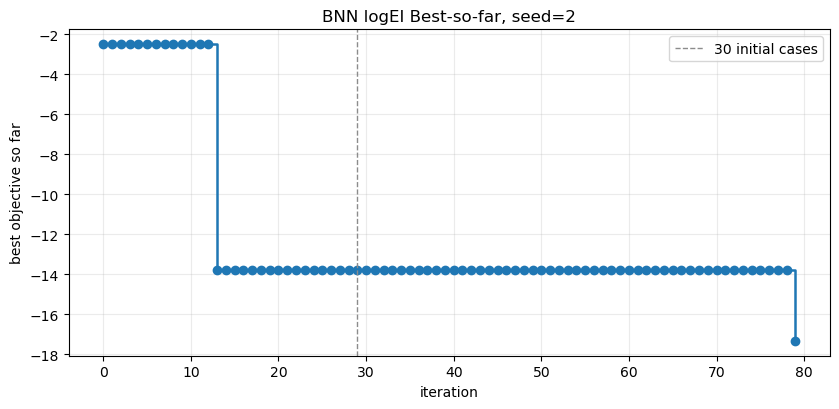

In [6]:
import matplotlib.pyplot as plt

if history_df.empty:
    print('No selected completed seed history available.')
else:
    plot_df = history_df.copy().sort_values('iteration')
    if 'best_so_far' not in plot_df and 'objective' in plot_df:
        plot_df['objective'] = pd.to_numeric(plot_df['objective'], errors='coerce')
        plot_df['best_so_far'] = plot_df['objective'].cummin()
    plot_df['best_so_far'] = pd.to_numeric(plot_df['best_so_far'], errors='coerce')
    finite_best = np.isfinite(plot_df['best_so_far'])

    if not finite_best.any():
        print('No finite best_so_far values found for selected seed.')
    else:
        fig, ax = plt.subplots(figsize=(8.5, 4.2))
        ax.plot(
            plot_df.loc[finite_best, 'iteration'],
            plot_df.loc[finite_best, 'best_so_far'],
            marker='o',
            lw=1.8,
            drawstyle='steps-post',
        )
        ax.axvline(N_INIT - 1, color='0.55', ls='--', lw=1.0, label=f'{N_INIT} initial cases')
        ax.set_title(f'BNN logEI Best-so-far, seed={int(plot_df["seed"].iloc[0])}')
        ax.set_xlabel('iteration')
        ax.set_ylabel('best objective so far')
        ax.grid(True, alpha=0.25)
        ax.legend(loc='best')
        plt.tight_layout()


Compact BNN logEI campaign metrics:


,seed,run_id,method,status,best_objective,first_feasible_iteration,cache_hit_ratio,runtime_engine_sec,runtime_sim_sec,num_trials
0,0,bnn_online_general_seed0,bnn_response_qlogei,completed,-24.999434,NaN,0.7250,1348.922068,17739.488545,80
1,1,bnn_online_general_seed1,bnn_response_qlogei,completed,-19.161885,NaN,0.6000,4556.488843,86982.289696,80
2,2,bnn_online_general_seed2,bnn_response_qlogei,completed,-17.341530,NaN,0.6625,974.845831,27835.061825,80


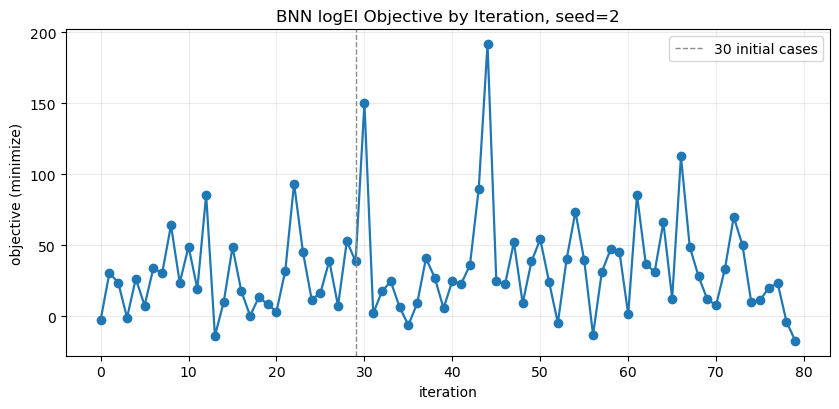

In [7]:
if history_df.empty:
    print('No selected completed seed history available.')
else:
    import matplotlib.pyplot as plt

    plot_df = history_df.copy().sort_values('iteration')
    plot_df['objective'] = pd.to_numeric(plot_df.get('objective'), errors='coerce')
    finite_obj = np.isfinite(plot_df['objective'])

    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    if finite_obj.any():
        ax.plot(plot_df.loc[finite_obj, 'iteration'], plot_df.loc[finite_obj, 'objective'], marker='o', lw=1.6)
    ax.axvline(N_INIT - 1, color='0.55', ls='--', lw=1.0, label=f'{N_INIT} initial cases')
    ax.set_title(f'BNN logEI Objective by Iteration, seed={int(plot_df["seed"].iloc[0])}')
    ax.set_xlabel('iteration')
    ax.set_ylabel('objective (minimize)')
    ax.grid(True, alpha=0.25)
    ax.legend(loc='best')
    plt.tight_layout()

    if not campaign_summary_df.empty:
        cols = [
            'seed', 'run_id', 'method', 'status', 'best_objective',
            'first_feasible_iteration', 'cache_hit_ratio',
            'runtime_engine_sec', 'runtime_sim_sec', 'num_trials',
        ]
        cols = [col for col in cols if col in campaign_summary_df.columns]
        print('Compact BNN logEI campaign metrics:')
        display(campaign_summary_df[cols])


,iteration,obj_min,obj_max,obj_mean,n
0,0,-2.504020,79.669474,41.219501,3
1,1,17.264189,64.236110,37.347796,3
2,2,23.758582,86.405734,49.459588,3
3,3,-1.022862,30.353112,16.859925,3
4,4,26.509320,63.184710,39.946561,3
5,5,7.530026,51.607633,23.213098,3
6,6,17.289816,42.708086,31.316270,3
7,7,-2.214530,30.382270,15.810205,3
8,8,54.704456,64.053661,60.099409,3
9,9,-17.863279,24.040910,9.923758,3


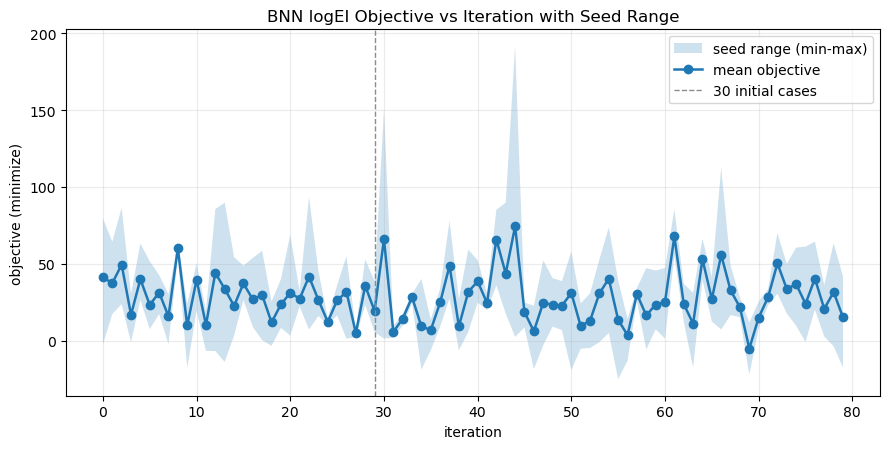

In [8]:
# Objective vs iteration with range band across completed configured seeds.
import matplotlib.pyplot as plt

if all_hist_df.empty or 'objective' not in all_hist_df:
    print('No completed objective history available.')
else:
    objective_df = all_hist_df[['seed', 'iteration', 'objective']].copy()
    objective_df['iteration'] = pd.to_numeric(objective_df['iteration'], errors='coerce')
    objective_df['objective'] = pd.to_numeric(objective_df['objective'], errors='coerce')
    objective_df = objective_df[np.isfinite(objective_df['iteration']) & np.isfinite(objective_df['objective'])]

    if objective_df.empty:
        print('No finite objective/iteration rows found.')
    else:
        range_df = (
            objective_df
            .groupby('iteration', as_index=False)['objective']
            .agg(obj_min='min', obj_max='max', obj_mean='mean', n='count')
            .sort_values('iteration')
            .reset_index(drop=True)
        )

        fig, ax = plt.subplots(figsize=(9.0, 4.6))
        ax.fill_between(
            range_df['iteration'],
            range_df['obj_min'],
            range_df['obj_max'],
            alpha=0.22,
            label='seed range (min-max)',
        )
        ax.plot(range_df['iteration'], range_df['obj_mean'], lw=1.8, marker='o', label='mean objective')
        ax.axvline(N_INIT - 1, color='0.55', ls='--', lw=1.0, label=f'{N_INIT} initial cases')
        ax.set_title('BNN logEI Objective vs Iteration with Seed Range')
        ax.set_xlabel('iteration')
        ax.set_ylabel('objective (minimize)')
        ax.grid(True, alpha=0.25)
        ax.legend(loc='best')
        plt.tight_layout()

        display(range_df.head(20))


,iteration,best_min,best_max,best_mean,n
0,0,-2.504020,79.669474,41.219501,3
1,1,-2.504020,46.493050,20.417740,3
2,2,-2.504020,38.214449,17.658206,3
3,3,-2.504020,21.249523,12.003231,3
4,4,-2.504020,21.249523,12.003231,3
5,5,-2.504020,17.264189,8.420601,3
6,6,-2.504020,17.264189,8.420601,3
7,7,-2.504020,10.501635,1.927695,3
8,8,-2.504020,10.501635,1.927695,3
9,9,-17.863279,10.501635,-3.288555,3


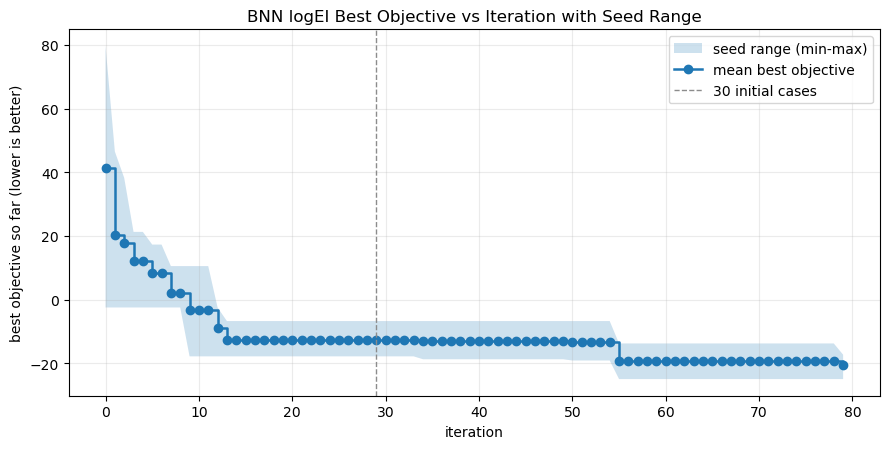

In [9]:
# Best objective (best-so-far) vs iteration with range band across completed configured seeds.
import matplotlib.pyplot as plt

if all_hist_df.empty:
    print('No completed best-objective history available.')
else:
    best_df = all_hist_df.copy()
    best_df['iteration'] = pd.to_numeric(best_df['iteration'], errors='coerce')
    if 'best_so_far' in best_df:
        best_df['best_so_far'] = pd.to_numeric(best_df['best_so_far'], errors='coerce')
    elif 'objective' in best_df:
        best_df['objective'] = pd.to_numeric(best_df['objective'], errors='coerce')
        best_df = best_df.sort_values(['seed', 'iteration'])
        best_df['best_so_far'] = best_df.groupby('seed')['objective'].cummin()
    else:
        best_df['best_so_far'] = np.nan

    best_df = best_df[np.isfinite(best_df['iteration']) & np.isfinite(best_df['best_so_far'])]

    if best_df.empty:
        print('No finite best objective history found.')
    else:
        best_range_df = (
            best_df
            .groupby('iteration', as_index=False)['best_so_far']
            .agg(best_min='min', best_max='max', best_mean='mean', n='count')
            .sort_values('iteration')
            .reset_index(drop=True)
        )

        fig, ax = plt.subplots(figsize=(9.0, 4.6))
        ax.fill_between(
            best_range_df['iteration'],
            best_range_df['best_min'],
            best_range_df['best_max'],
            alpha=0.22,
            label='seed range (min-max)',
        )
        ax.plot(
            best_range_df['iteration'],
            best_range_df['best_mean'],
            marker='o',
            lw=1.8,
            drawstyle='steps-post',
            label='mean best objective',
        )
        ax.axvline(N_INIT - 1, color='0.55', ls='--', lw=1.0, label=f'{N_INIT} initial cases')
        ax.set_title('BNN logEI Best Objective vs Iteration with Seed Range')
        ax.set_xlabel('iteration')
        ax.set_ylabel('best objective so far (lower is better)')
        ax.grid(True, alpha=0.25)
        ax.legend(loc='best')
        plt.tight_layout()

        display(best_range_df.head(20))


,method,final_median,final_mean,final_best,final_worst,seeds
0,BNN logEI,-19.161885,-20.500950,-24.999434,-17.341530,3
1,LHS,-19.161885,-18.814976,-25.141275,-9.847343,5
2,BO logEI,-14.657114,-15.649376,-23.813877,-8.052391,5


,method,iteration,best_median,best_mean,best_min,best_max,n
220,LHS,60,-16.272256,-17.835083,-25.141275,-9.847343,5
221,LHS,61,-16.272256,-17.835083,-25.141275,-9.847343,5
222,LHS,62,-18.769620,-18.728211,-25.141275,-9.847343,5
223,LHS,63,-18.769620,-18.728211,-25.141275,-9.847343,5
224,LHS,64,-18.769620,-18.728211,-25.141275,-9.847343,5
225,LHS,65,-18.769620,-18.728211,-25.141275,-9.847343,5
226,LHS,66,-18.769620,-18.728211,-25.141275,-9.847343,5
227,LHS,67,-18.769620,-18.728211,-25.141275,-9.847343,5
228,LHS,68,-18.769620,-18.728211,-25.141275,-9.847343,5
229,LHS,69,-18.769620,-18.728211,-25.141275,-9.847343,5


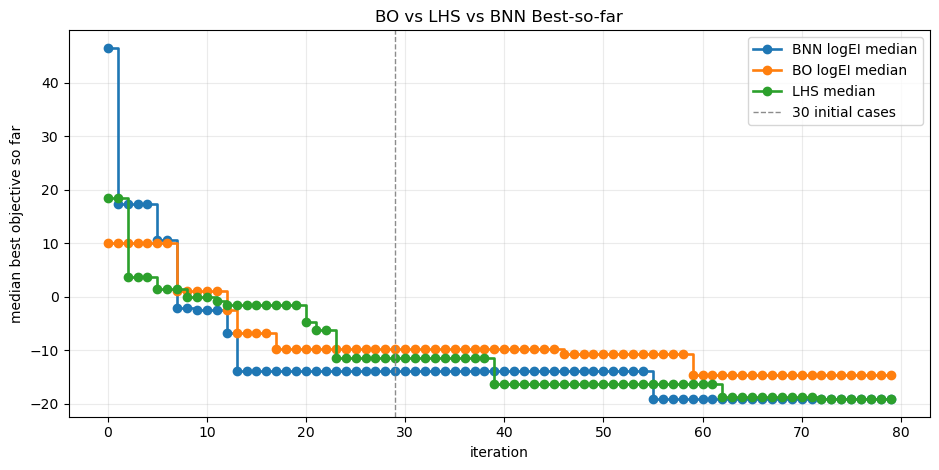

In [10]:
# Compare BO, LHS, and BNN best-so-far curves from completed checkpoints.
import matplotlib.pyplot as plt


def _load_method_best_histories(method: str, root: Path) -> pd.DataFrame:
    rows: list[pd.DataFrame] = []
    if not root.exists():
        return pd.DataFrame(columns=['method', 'seed', 'iteration', 'best_so_far'])
    seed_pattern = re.compile(r'.*_seed(\d+)\.checkpoint\.json$')
    for ckpt_path in sorted(root.glob('*.checkpoint.json')):
        payload = json.loads(ckpt_path.read_text(encoding='utf-8'))
        hist = pd.DataFrame(payload.get('history', []))
        if LOAD_COMPLETED_ONLY and len(hist) < TARGET_TRIALS:
            continue
        if hist.empty or 'iteration' not in hist:
            continue
        seed_value = payload.get('seed')
        if seed_value is None:
            match = seed_pattern.match(ckpt_path.name)
            seed_value = int(match.group(1)) if match else None
        hist = hist.copy()
        hist['iteration'] = pd.to_numeric(hist['iteration'], errors='coerce')
        if 'best_so_far' in hist:
            hist['best_so_far'] = pd.to_numeric(hist['best_so_far'], errors='coerce')
        elif 'objective' in hist:
            hist['objective'] = pd.to_numeric(hist['objective'], errors='coerce')
            hist = hist.sort_values('iteration')
            hist['best_so_far'] = hist['objective'].cummin()
        else:
            continue
        hist = hist[np.isfinite(hist['iteration']) & np.isfinite(hist['best_so_far'])]
        if hist.empty:
            continue
        hist['iteration'] = hist['iteration'].astype(int)
        hist['seed'] = seed_value
        hist['method'] = method
        rows.append(hist[['method', 'seed', 'iteration', 'best_so_far']])
    if not rows:
        return pd.DataFrame(columns=['method', 'seed', 'iteration', 'best_so_far'])
    return pd.concat(rows, ignore_index=True)


comparison_histories = pd.concat(
    [_load_method_best_histories(method, root) for method, root in COMPARISON_METHOD_ROOTS.items()],
    ignore_index=True,
)

if comparison_histories.empty:
    print('No completed BO/LHS/BNN checkpoints found for comparison.')
else:
    summary = (
        comparison_histories
        .groupby(['method', 'iteration'], as_index=False)['best_so_far']
        .agg(best_median='median', best_mean='mean', best_min='min', best_max='max', n='count')
        .sort_values(['method', 'iteration'])
        .reset_index(drop=True)
    )

    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    for method, method_df in summary.groupby('method', sort=False):
        method_df = method_df.sort_values('iteration')
        ax.plot(
            method_df['iteration'],
            method_df['best_median'],
            marker='o',
            lw=1.9,
            drawstyle='steps-post',
            label=f'{method} median',
        )
    ax.axvline(N_INIT - 1, color='0.55', ls='--', lw=1.0, label=f'{N_INIT} initial cases')
    ax.set_title('BO vs LHS vs BNN Best-so-far')
    ax.set_xlabel('iteration')
    ax.set_ylabel('median best objective so far')
    ax.grid(True, alpha=0.25)
    ax.legend(loc='best')
    plt.tight_layout()

    final_rows = (
        comparison_histories
        .sort_values('iteration')
        .groupby(['method', 'seed'], as_index=False)
        .tail(1)
        .groupby('method', as_index=False)['best_so_far']
        .agg(final_median='median', final_mean='mean', final_best='min', final_worst='max', seeds='count')
        .sort_values('final_median')
        .reset_index(drop=True)
    )
    display(final_rows)
    display(summary.tail(20))
